# 02 | Lenguaje de títulos y rendimiento de videos
## Laboratorio de Procesamiento de Lenguaje Natural
**Archivo:** `videos-stats.csv` · **Modalidad:** individual o en parejas · **Entorno:** CPU.

**Pregunta guía:** ¿qué temas aparecen en los títulos y cómo se relacionan, de manera descriptiva, con las estadísticas guardadas de los videos?

Recorrido: cargar y auditar → consolidar videos → limpiar y tokenizar títulos → comparar distribuciones → TF-IDF → agrupación exploratoria → relaciones estadísticas → informe PDF.

**Cómo comenzar:** abra este cuaderno en Google Colab y ejecute las celdas numeradas en orden. Cargue `videos-stats.csv` cuando se solicite. No depende del cuaderno ni del CSV de comentarios. Código visible, sin formularios, sin ejecución ni salidas guardadas.

**Antes de interpretar:** `Keyword` es una palabra clave del archivo, no necesariamente una categoría oficial de YouTube. Las estadísticas son una fotografía histórica con fecha de captura desconocida. No permiten medir crecimiento, predecir viralidad por sí solas ni demostrar que el título causa las visualizaciones.

## Celda 01. Preparar el entorno

Instala bibliotecas ausentes y registra versiones; el análisis se ejecuta en CPU.

In [1]:
# Instala únicamente bibliotecas ausentes. No actualiza las que ya funcionan.
import importlib, subprocess, sys
DEPENDENCIAS = {
    "numpy": "numpy>=1.24,<3", "pandas": "pandas>=2,<3",
    "matplotlib": "matplotlib>=3.7,<4", "sklearn": "scikit-learn>=1.3,<2",
    "scipy": "scipy>=1.10,<2", "reportlab": "reportlab>=4,<5",
    "nltk": "nltk>=3.8,<4",
}
for modulo, paquete in DEPENDENCIAS.items():
    try:
        importlib.import_module(modulo)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import re, html, json, hashlib, zipfile, shutil, platform, unicodedata
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, FileLink
import sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

VERSIONES = {m: getattr(importlib.import_module(m), "__version__", "disponible")
             for m in DEPENDENCIAS}
print("Entorno preparado. No se necesita GPU ni una clave de API.")
display(pd.DataFrame(VERSIONES.items(), columns=["Biblioteca", "Versión"]))

Entorno preparado. No se necesita GPU ni una clave de API.


,Biblioteca,Versión
0,numpy,2.5.3
1,pandas,3.0.5
2,matplotlib,3.11.2
3,sklearn,1.9.1
4,scipy,1.18.1
5,reportlab,5.0.1
6,nltk,3.10.4


## Celda 02. Identificación y parámetros

Cambie nombre y grupo. TOP controla los rankings; K_GRUPOS controla una agrupación exploratoria, no una clasificación de calidad.

In [2]:
ESTUDIANTE = "Por completar"
GRUPO = "Por completar"
SEMILLA = 42
TOP = 10
MIN_VIDEOS_POR_KEYWORD = 10
K_GRUPOS = 6
DEMOSTRAR_LEMAS = True
DESCARGAR_AL_FINAL = True
SALIDA = Path("salida_videos")
GRAFICOS = SALIDA / "graficos"
GRAFICOS.mkdir(parents=True, exist_ok=True)
FECHA_ANALISIS = datetime.now(ZoneInfo("America/Bogota")).strftime("%Y-%m-%d %H:%M %Z")
PARAMETROS = {"semilla":SEMILLA,"top":TOP,"k_grupos":K_GRUPOS,
              "min_videos_keyword":MIN_VIDEOS_POR_KEYWORD,"componentes_lsa_max":50,
              "duplicados":"primera fila por Video ID; keywords preservadas"}
print("Carpeta de resultados:",SALIDA)

Carpeta de resultados: salida_videos


## Celda 03. Funciones de lectura, texto y gráficos

Se reutilizan funciones de formato, tokenización y visualización. Los datos originales se conservan.

In [3]:
def numero(valor, decimales=0):
    """Formato numérico colombiano para tablas, gráficos e informe."""
    if pd.isna(valor):
        return "N/D"
    return f"{valor:,.{decimales}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def cargar_csv(nombre, requeridas):
    """Lee un archivo local o solicita su carga en Google Colab."""
    ruta = Path(nombre)
    if not ruta.is_file():
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(f"Coloque {nombre} junto al cuaderno.") from exc
        print(f"Seleccione {nombre}, no el otro CSV.")
        subidos = files.upload()
        candidatos = [Path(x) for x in subidos if x.lower().endswith(".csv")]
        if not ruta.is_file():
            if len(candidatos) != 1:
                raise ValueError("Cargue únicamente el CSV solicitado y repita esta celda.")
            ruta = candidatos[0]
    tabla = pd.read_csv(ruta, encoding="utf-8-sig")
    tabla.columns = tabla.columns.astype(str).str.strip()
    faltan = set(requeridas) - set(tabla.columns)
    if faltan:
        raise ValueError(f"El archivo no tiene estas columnas: {sorted(faltan)}")
    if tabla.empty:
        raise ValueError("El CSV está vacío.")
    return tabla, ruta

def eje(titulo, subtitulo, alto=4.6):
    """Una figura por gráfico, sin 3D ni ejes dobles."""
    fig = plt.figure(figsize=(10.8, alto))
    ax = fig.add_subplot(111)
    fig.suptitle(titulo, x=0.02, ha="left", fontsize=16, fontweight="bold", y=0.98)
    fig.text(0.02, 0.88, subtitulo, ha="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=10)
    ax.set_axisbelow(True)
    return fig, ax

def guardar_grafico(fig, nombre):
    fig.tight_layout(rect=(0, 0.03, 1, 0.83))
    ruta = GRAFICOS / (nombre + ".png")
    fig.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return ruta

def barras(etiquetas, valores, titulo, subtitulo, nombre, unidad="", decimales=0,
           notas=None, limite=None):
    # El orden de entrada es el orden que ve el lector: primero el más relevante.
    fig, ax = eje(titulo, subtitulo)
    y = np.arange(len(valores)); valores = np.asarray(valores, dtype=float)
    ax.barh(y, valores)
    ax.set_yticks(y, [str(x) for x in etiquetas]); ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.18)
    mayor = max(float(np.nanmax(valores)), 1e-9)
    ax.set_xlim(0, limite if limite else mayor * 1.25)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: numero(x, decimales)))
    ax.set_xlabel(unidad)
    for i, valor in enumerate(valores):
        etiqueta = numero(valor, decimales)
        if notas is not None:
            etiqueta += " | " + str(notas[i])
        ax.annotate(etiqueta, (valor, i), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=9)
    return guardar_grafico(fig, nombre)

# Las listas de palabras vacías se usan para explorar vocabulario, no para borrar
# automáticamente palabras del modelo de sentimiento.
STOP_ES = set("el la los las de del un una unos unas y o que en a al con por para es son se su sus lo como este esta estos estas mi mis tu tus me te le les ya muy mas pero si hay desde sobre entre".split())
STOP = (set(ENGLISH_STOP_WORDS) | STOP_ES) - {"no", "not", "nor", "never", "nunca", "sin"}
PATRON = r"(?u)\b[^\W\d_][\w']*\b"

def normalizar(texto):
    """No modifica el original; conserva acentos, negaciones y puntuación."""
    t = unicodedata.normalize("NFKC", html.unescape(str(texto))).lower()
    t = t.replace("’", "'").replace("‘", "'")
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"\bwon't\b", "will not", t)
    t = re.sub(r"\bcan't\b", "can not", t)
    t = re.sub(r"n't\b", " not", t)
    return re.sub(r"\s+", " ", t).strip()

def tokenizar(texto):
    return re.findall(PATRON, texto)

def tabla_vocabulario(series, top=10):
    # Frecuencia documental: cada término cuenta máximo una vez en cada texto.
    vec = CountVectorizer(token_pattern=PATRON, lowercase=False, binary=True,
                          stop_words=sorted(STOP), min_df=2)
    matriz = vec.fit_transform(series)
    conteos = np.asarray(matriz.sum(axis=0)).ravel()
    tabla = pd.DataFrame({"Término": vec.get_feature_names_out(), "Textos": conteos})
    tabla["Porcentaje"] = 100 * tabla["Textos"] / len(series)
    return tabla.sort_values(["Textos", "Término"], ascending=[False, True]), vec, matriz

print("Funciones listas. Los originales permanecen intactos.")

Funciones listas. Los originales permanecen intactos.


## Celda 04. Cargar y diagnosticar el archivo

Una fila original puede repetir un video bajo otra palabra clave; por eso fila y video no siempre significan lo mismo.

In [4]:
original, RUTA_CSV = cargar_csv("videos-stats.csv",["Title","Video ID","Published At","Keyword","Likes","Comments","Views"])
print("Registros:",numero(len(original)),"| Videos distintos:",numero(original["Video ID"].nunique()))
display(original.head(5))
diagnostico = pd.DataFrame({"Columna":original.columns,"Tipo":original.dtypes.astype(str).values,
                            "Vacíos":original.isna().sum().values})
display(diagnostico)

Registros: 1.881 | Videos distintos: 1.869


,Unnamed: 0,Title,Video ID,Published At,Keyword,Likes,Comments,Views
0,0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0
3,3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,kXiYSI7H2b0,2022-08-23,tech,71566.0,1426.0,922918.0
4,4,Best Back to School Tech 2022!,ErMwWXQxHp0,2022-08-08,tech,96513.0,5155.0,1855644.0


,Columna,Tipo,Vacíos
0,Unnamed: 0,int64,0
1,Title,str,0
2,Video ID,str,0
3,Published At,str,0
4,Keyword,str,0
5,Likes,float64,2
6,Comments,float64,2
7,Views,float64,2


## Celda 05. Limpiar y consolidar sin inflar los totales

Los conteos negativos se convierten en datos faltantes. Se conserva la primera fila completa por video, porque no existe una fecha de captura para decidir cuál es más reciente. Las palabras clave se preservan en una tabla aparte.

In [5]:
base = original.loc[:,~original.columns.str.match(r"^Unnamed")].copy()
base["registro_origen"] = base.index
sin_id = base["Video ID"].isna() | base["Video ID"].fillna("").astype(str).str.strip().eq("")
rechazados = base[sin_id].copy()
base = base.loc[~sin_id].copy()
base["Video ID"] = base["Video ID"].astype(str).str.strip()
base["Title"] = base["Title"].fillna("").astype(str)
base["Keyword"] = base["Keyword"].fillna("Sin palabra clave").astype(str).str.strip().replace("","Sin palabra clave")
controles_numericos = []
for col in ["Likes","Comments","Views"]:
    antes = pd.to_numeric(base[col],errors="coerce")
    negativos = int(antes.lt(0).sum())
    controles_numericos.append((col,int(antes.isna().sum()),negativos))
    base[col] = antes.mask(antes.lt(0))
base["fecha_publicacion"] = pd.to_datetime(base["Published At"],errors="coerce")
registros_repetidos = base[base["Video ID"].duplicated(keep=False)].copy()
# Detecta diferencias entre filas del mismo video; no suma esas estadísticas.
conflictos_por_id = base.groupby("Video ID")[["Title","Published At","Likes","Comments","Views"]].nunique(dropna=False)
ids_conflictivos = conflictos_por_id.index[conflictos_por_id.gt(1).any(axis=1)]
mapa_keywords = base[["Video ID","Keyword"]].drop_duplicates().reset_index(drop=True)
keywords_por_video = mapa_keywords.groupby("Video ID")["Keyword"].agg(lambda s:" | ".join(sorted(set(s))))
videos = base.drop_duplicates("Video ID",keep="first").copy()
videos["keywords_asociadas"] = videos["Video ID"].map(keywords_por_video)
videos["titulo_legible"] = videos["Title"].map(html.unescape)
videos = videos.reset_index(drop=True)
if len(videos) < 30:
    raise ValueError("Este laboratorio requiere al menos 30 videos válidos.")
calidad_numerica = pd.DataFrame(controles_numericos,columns=["Variable","Vacíos o no numéricos (filas)","Negativos (filas)"])
auditoria = pd.DataFrame([
 ("Registros originales",len(original)),("Registros sin ID excluidos",len(rechazados)),
 ("Filas adicionales del mismo video",len(base)-len(videos)),
 ("Videos con valores distintos entre registros",len(ids_conflictivos)),
 ("Videos únicos conservados",len(videos)),
 ("Videos sin visualizaciones válidas",int(videos["Views"].isna().sum())),
 ("Fechas inválidas en videos únicos",int(videos["fecha_publicacion"].isna().sum()))
],columns=["Control","Cantidad"])
display(auditoria); display(calidad_numerica)
assert videos["Video ID"].is_unique
print("Las comparaciones por Keyword pueden incluir el mismo video en varios grupos; no son sumables.")

,Control,Cantidad
0,Registros originales,1881
1,Registros sin ID excluidos,0
2,Filas adicionales del mismo video,12
3,Videos con valores distintos entre registros,9
4,Videos únicos conservados,1869
5,Videos sin visualizaciones válidas,2
6,Fechas inválidas en videos únicos,0


,Variable,Vacíos o no numéricos (filas),Negativos (filas)
0,Likes,2,7
1,Comments,2,2
2,Views,2,0


Las comparaciones por Keyword pueden incluir el mismo video en varios grupos; no son sumables.


## Celda 06. Normalizar títulos y extraer características

Se conservan títulos originales y decodificados. La cantidad de palabras es una característica lingüística, no una causa demostrada de éxito.

In [6]:
videos["titulo_normalizado"] = videos["titulo_legible"].map(normalizar)
videos["tokens"] = videos["titulo_normalizado"].map(tokenizar)
videos["n_palabras_titulo"] = videos["tokens"].map(len)
videos["n_caracteres_titulo"] = videos["titulo_legible"].str.len()
videos["titulo_pregunta"] = videos["titulo_legible"].str.contains("?",regex=False)
videos["titulo_exclamacion"] = videos["titulo_legible"].str.contains("!",regex=False)
# Proporción descriptiva, NO una tasa oficial de usuarios únicos comprometidos.
# Si falta Likes, Comments o Views, el resultado queda vacío.
valida = videos["Views"].gt(0) & videos[["Likes","Comments"]].notna().all(axis=1)
videos["interacciones_por_100_vistas"] = np.nan
videos.loc[valida,"interacciones_por_100_vistas"] = (
    100*(videos.loc[valida,"Likes"]+videos.loc[valida,"Comments"])/videos.loc[valida,"Views"])
videos["likes_por_100_vistas"] = 100*videos["Likes"]/videos["Views"].where(videos["Views"]>0)
videos["ratio_mayor_100"] = videos["interacciones_por_100_vistas"].gt(100)
display(videos[["titulo_legible","titulo_normalizado","tokens","n_palabras_titulo"]].head(4))
print("Proporción calculable en",numero(valida.sum()),"videos. Valores mayores a 100:",int(videos.ratio_mayor_100.sum()))

,titulo_legible,titulo_normalizado,tokens,n_palabras_titulo
0,Apple Pay Is Killing the Physical Wallet After...,apple pay is killing the physical wallet after...,"[apple, pay, is, killing, the, physical, walle...",16
1,The most EXPENSIVE thing I own.,the most expensive thing i own.,"[the, most, expensive, thing, i, own]",6
2,My New House Gaming Setup is SICK!,my new house gaming setup is sick!,"[my, new, house, gaming, setup, is, sick]",7
3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,petrol vs liquid nitrogen | freezing experimen...,"[petrol, vs, liquid, nitrogen, freezing, exper...",19


Proporción calculable en 1.859 videos. Valores mayores a 100: 0


## Celda 07. Lematización como demostración

La demostración es para palabras inglesas con categoría gramatical conocida. El corpus de títulos conserva sus idiomas; no se traduce automáticamente.

In [7]:
# Demostración opcional: WordNet necesita descargar un recurso la primera vez.
# No se aplica indiscriminadamente a todo el corpus, que puede ser multilingüe.
# pos='n': sustantivo; pos='v': verbo. El contexto gramatical cambia el resultado.
estado_lemas = "Demostración desactivada; no se aplicó al modelo."
if DEMOSTRAR_LEMAS:
    import nltk
    from nltk.stem import WordNetLemmatizer
    try:
        lematizador = WordNetLemmatizer()
        try:
            lematizador.lemmatize("videos", pos="n")
        except LookupError:
            if not nltk.download("wordnet", quiet=True, raise_on_error=False):
                raise RuntimeError("No fue posible descargar WordNet.")
        ejemplos_lemas = [("videos", "n"), ("comments", "n"), ("running", "v"),
                          ("liked", "v"), ("better", "a")]
        tabla_lemas = pd.DataFrame([
            {"Palabra": w, "Categoría gramatical": p,
             "Lema": lematizador.lemmatize(w, pos=p)} for w, p in ejemplos_lemas])
        display(tabla_lemas)
        estado_lemas = "Demostración de WordNet realizada; no se aplicó al modelo."
    except (LookupError, RuntimeError, OSError) as exc:
        estado_lemas = "WordNet no disponible; se continuó sin lematización."
        print(estado_lemas, str(exc))
        print("El análisis y el PDF funcionan sin este recurso opcional.")
else:
    print(estado_lemas)

WordNet no disponible; se continuó sin lematización. No fue posible descargar WordNet.
El análisis y el PDF funcionan sin este recurso opcional.


[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


## Celda 08. Indicadores y estadística descriptiva

Compare promedio, mediana y percentiles. Los totales se calculan sobre videos únicos, sin sumar filas repetidas.

In [8]:
variables = ["Views","Likes","Comments","n_palabras_titulo","interacciones_por_100_vistas"]
estadisticas = videos[variables].describe(percentiles=[.25,.5,.75,.9,.95]).T.reset_index(names="Variable")
display(estadisticas.round(2))
total_vistas = videos["Views"].sum(min_count=1)
mediana_vistas = videos["Views"].median()
media_vistas = videos["Views"].mean()
mediana_interaccion = videos["interacciones_por_100_vistas"].median()
fecha_min,fecha_max = videos["fecha_publicacion"].min(),videos["fecha_publicacion"].max()
indicadores = pd.DataFrame([
 ("Videos únicos",numero(len(videos))), ("Visualizaciones conocidas, total",numero(total_vistas)),
 ("Visualizaciones, mediana",numero(mediana_vistas)), ("Visualizaciones, promedio",numero(media_vistas)),
 ("Interacciones por 100 vistas, mediana",numero(mediana_interaccion,2)),
 ("Publicación más antigua",str(fecha_min.date())),("Publicación más reciente",str(fecha_max.date()))
],columns=["Indicador","Valor"])
display(indicadores)
print("El periodo anterior corresponde a publicación, no a la fecha de recolección.")

,Variable,count,mean,std,min,25%,50%,75%,90%,95%,max
0,Views,1867.0,11653890.04,1.087891e+08,25.00,85121.50,589907.00,2804977.50,11489580.20,34272954.60,4.034122e+09
1,Likes,1861.0,169674.17,7.972270e+05,0.00,2707.00,14899.00,60991.00,241605.00,626889.00,1.644556e+07
2,Comments,1865.0,7834.65,3.793892e+04,0.00,202.00,820.00,3380.00,10918.00,26285.80,7.328180e+05
3,n_palabras_titulo,1869.0,8.79,3.510000e+00,0.00,6.00,8.00,11.00,13.00,15.00,2.700000e+01
4,interacciones_por_100_vistas,1859.0,3.73,2.860000e+00,0.02,1.76,3.04,4.86,7.13,9.44,2.633000e+01


,Indicador,Valor
0,Videos únicos,1.869
1,"Visualizaciones conocidas, total",21.757.812.700
2,"Visualizaciones, mediana",589.907
3,"Visualizaciones, promedio",11.653.890
4,"Interacciones por 100 vistas, mediana","3,04"
5,Publicación más antigua,2007-07-16
6,Publicación más reciente,2022-08-24


El periodo anterior corresponde a publicación, no a la fecha de recolección.


## Celda 09. Rankings gerenciales por palabra clave

Se muestran medianas para reducir la influencia de unos pocos videos extremos. El tamaño de cada grupo acompaña el resultado.

,Keyword,Videos,Vistas_validas,Mediana_vistas,Promedio_vistas,Ratios_validos,Mediana_interacciones_100
28,mrbeast,50,50,65074742.5,6.676400e+07,50,3.29
3,bed,44,44,9359070.5,5.389323e+07,44,1.36
10,cubes,50,50,5038323.0,1.503874e+07,50,2.06
0,animals,38,38,4466776.0,9.472396e+07,38,0.79
39,tutorial,50,50,2817913.5,6.761032e+06,50,2.87
17,google,45,45,2530836.0,1.033650e+08,44,2.44
14,food,48,48,2456819.0,5.252406e+06,48,2.36
19,how-to,48,48,2023665.5,7.809285e+06,48,3.03
36,sports,49,49,1945140.0,8.601205e+06,49,1.17
4,biology,47,47,1743151.0,4.121606e+06,47,2.24


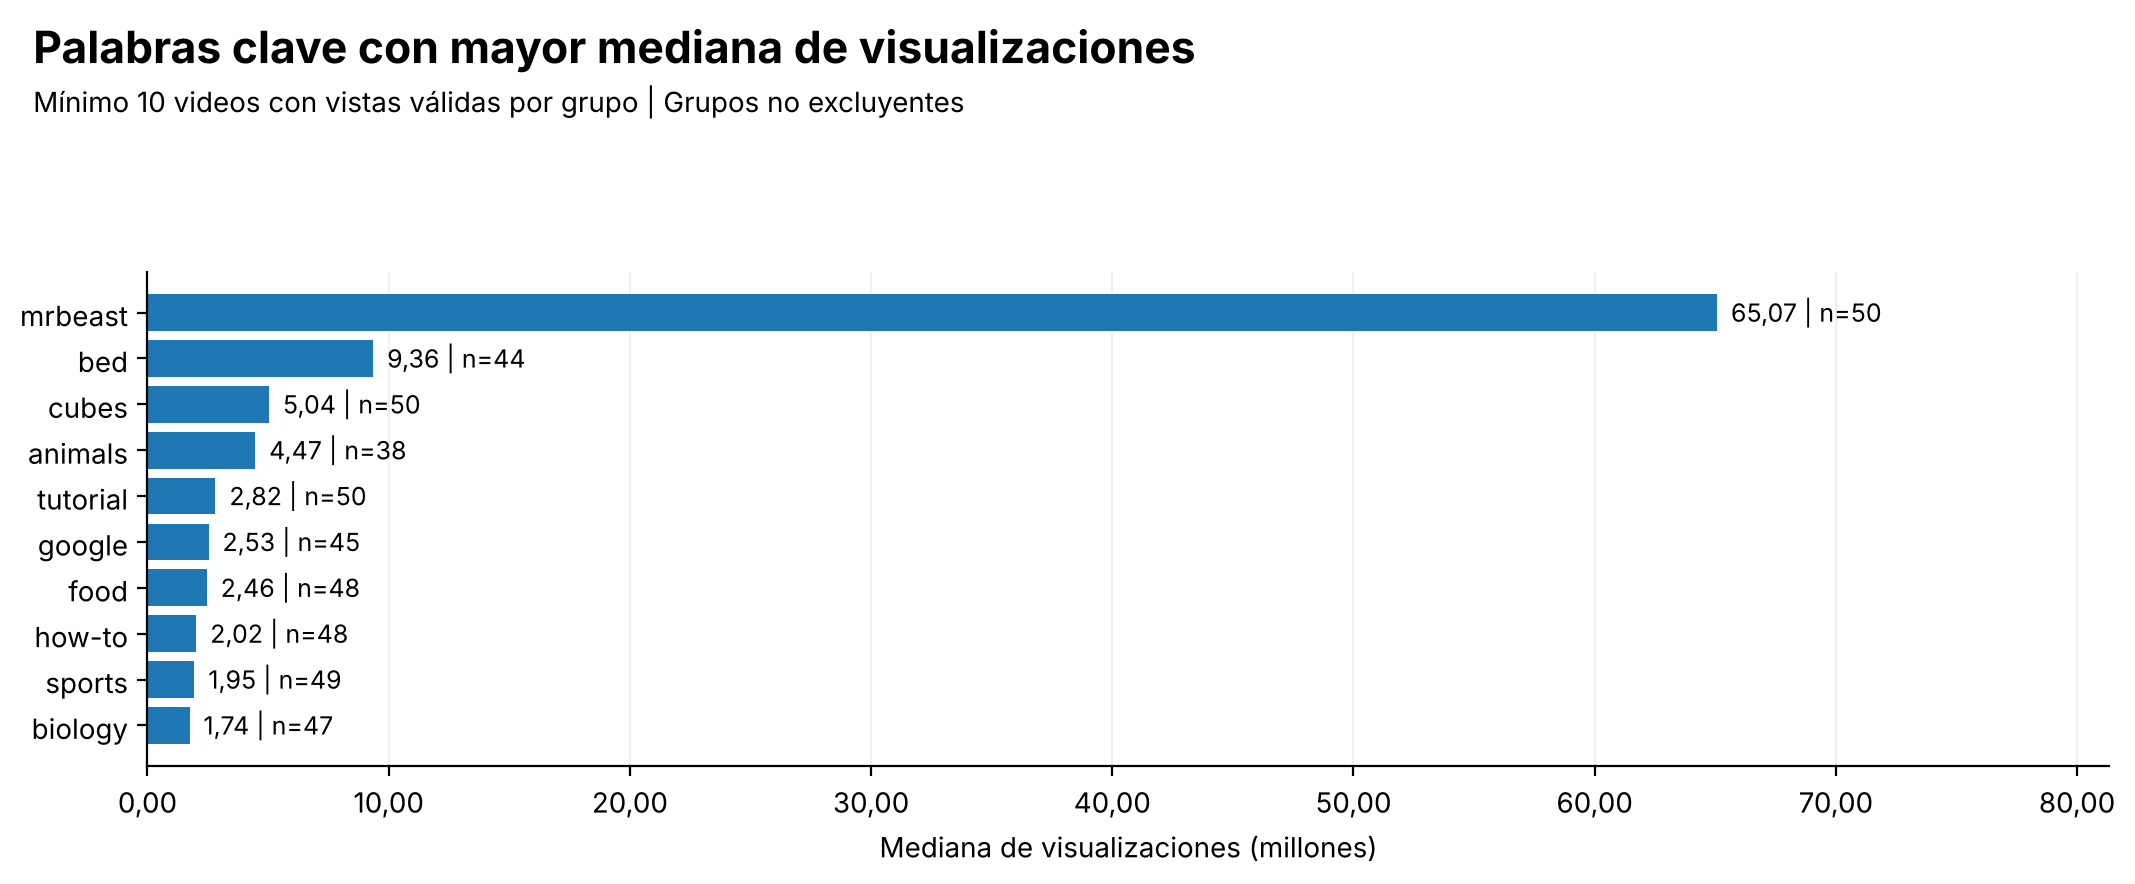

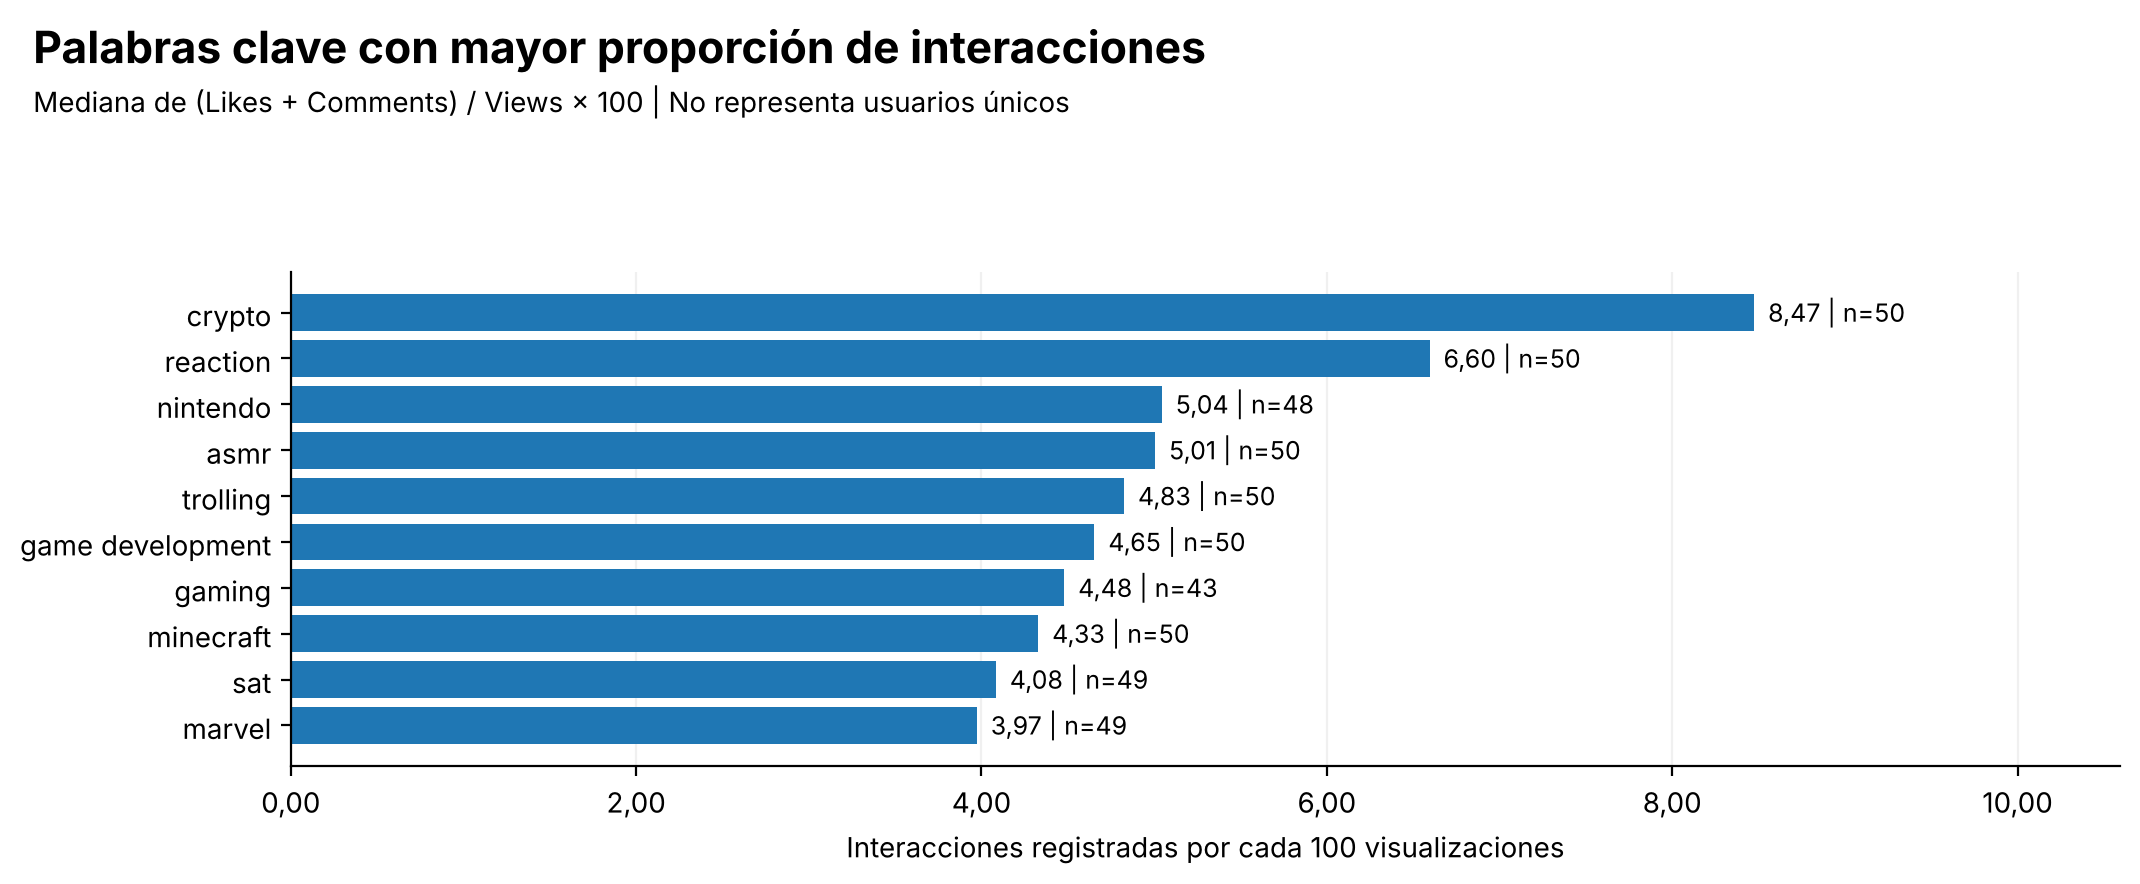

PosixPath('salida_videos/graficos/02_keyword_interaccion.png')

In [9]:
por_keyword = mapa_keywords.merge(videos.drop(columns=["Keyword"]),on="Video ID",how="left",validate="many_to_one")
resumen_keyword = por_keyword.groupby("Keyword").agg(
    Videos=("Video ID","nunique"), Vistas_validas=("Views","count"),
    Mediana_vistas=("Views","median"), Promedio_vistas=("Views","mean"),
    Ratios_validos=("interacciones_por_100_vistas","count"),
    Mediana_interacciones_100=("interacciones_por_100_vistas","median")
).reset_index()
ranking_vistas = resumen_keyword[resumen_keyword["Vistas_validas"]>=MIN_VIDEOS_POR_KEYWORD].nlargest(TOP,"Mediana_vistas")
ranking_ratio = resumen_keyword[resumen_keyword["Ratios_validos"]>=MIN_VIDEOS_POR_KEYWORD].nlargest(TOP,"Mediana_interacciones_100")
if ranking_vistas.empty or ranking_ratio.empty:
    raise ValueError("No hay grupos suficientes: reduzca MIN_VIDEOS_POR_KEYWORD y repita desde esta celda.")
display(ranking_vistas.round(2))
barras(ranking_vistas["Keyword"],ranking_vistas["Mediana_vistas"]/1e6,
 "Palabras clave con mayor mediana de visualizaciones",
 f"Mínimo {MIN_VIDEOS_POR_KEYWORD} videos con vistas válidas por grupo | Grupos no excluyentes",
 "01_keyword_vistas","Mediana de visualizaciones (millones)",2,
 notas=["n="+numero(x) for x in ranking_vistas["Vistas_validas"]])
barras(ranking_ratio["Keyword"],ranking_ratio["Mediana_interacciones_100"],
 "Palabras clave con mayor proporción de interacciones",
 "Mediana de (Likes + Comments) / Views × 100 | No representa usuarios únicos",
 "02_keyword_interaccion","Interacciones registradas por cada 100 visualizaciones",2,
 notas=["n="+numero(x) for x in ranking_ratio["Ratios_validos"]])

## Celda 10. Concentración de visualizaciones

Un ranking de videos y una curva acumulada muestran cuánto pesan los videos más vistos. La curva no es una evolución en el tiempo.

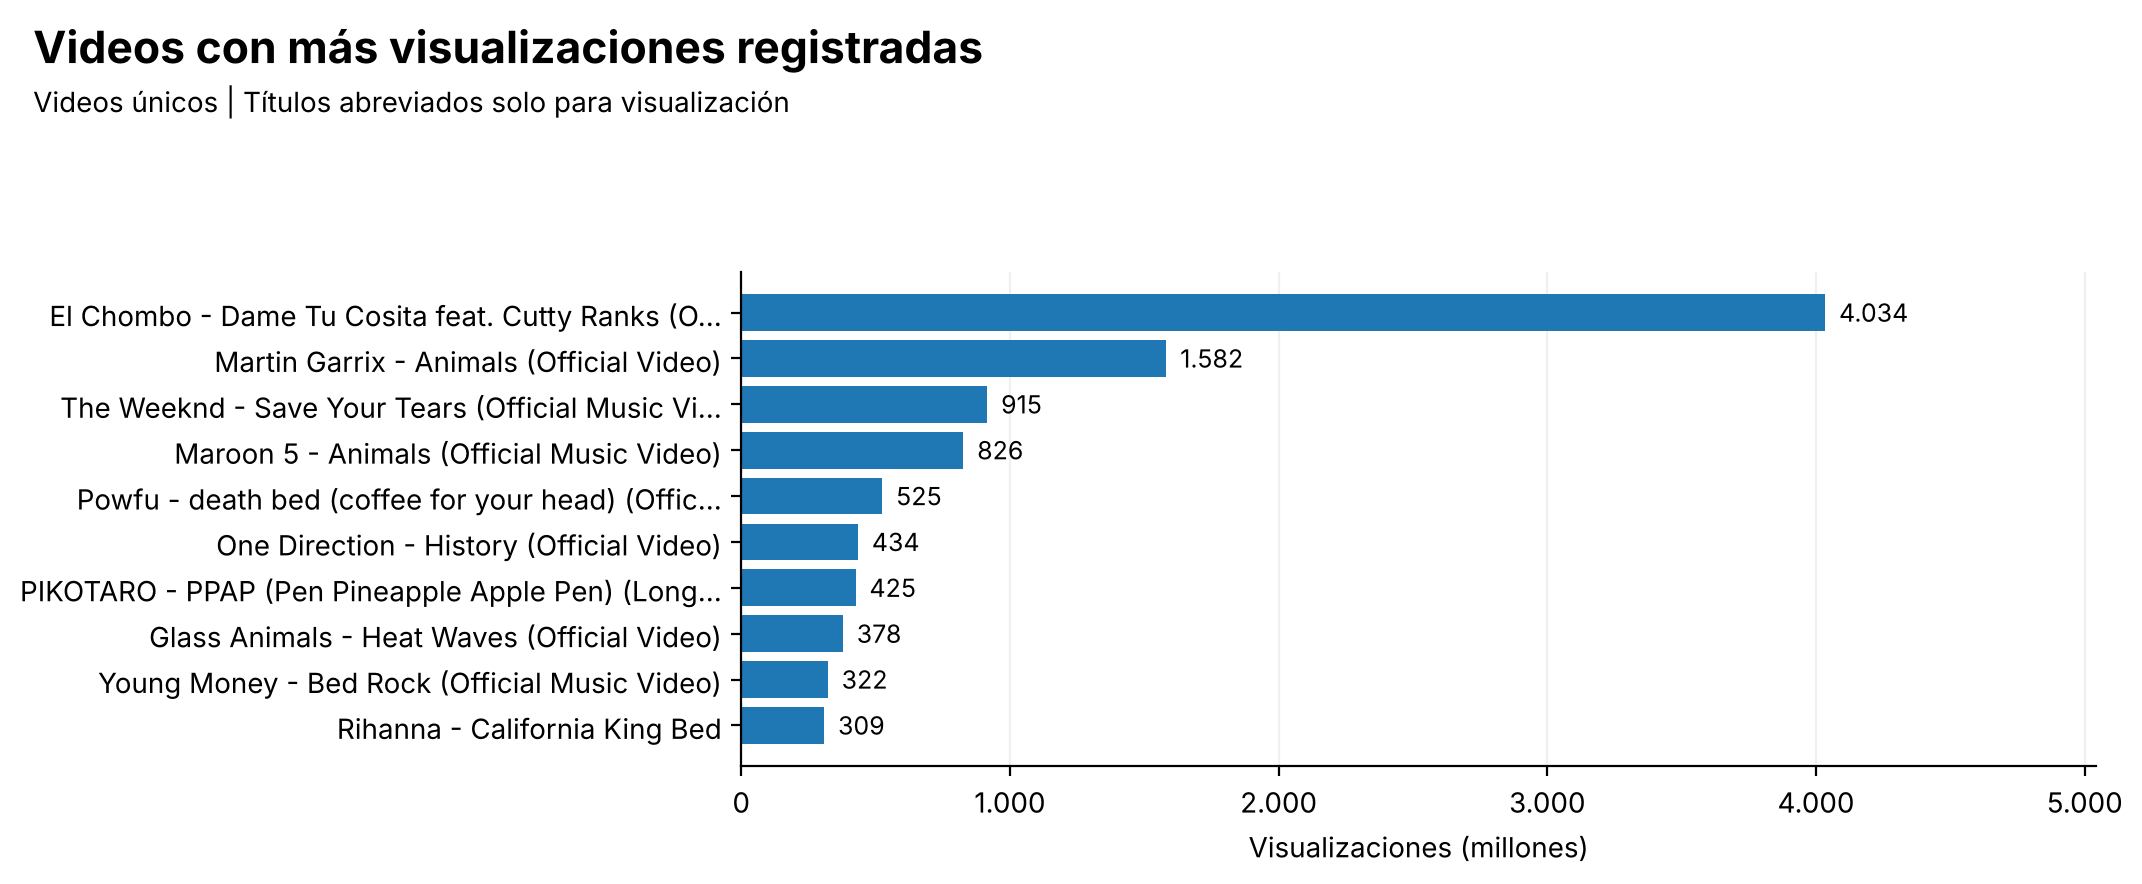

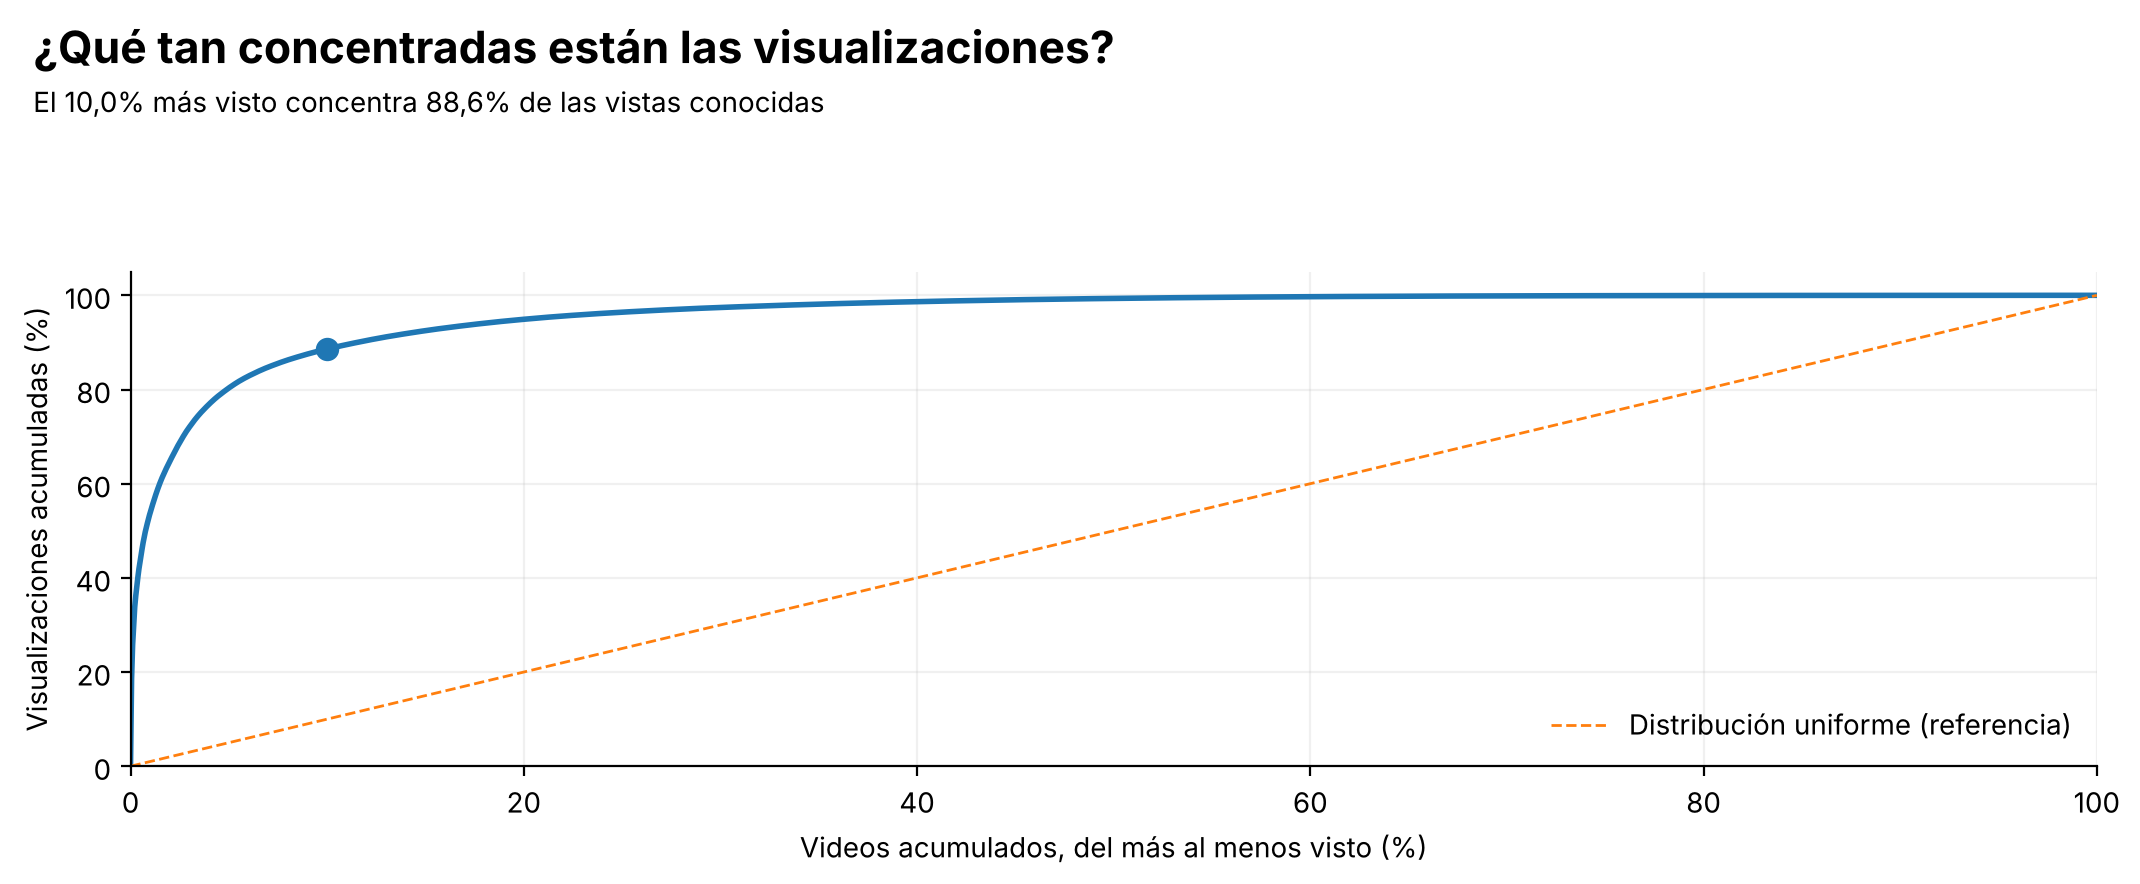

PosixPath('salida_videos/graficos/04_concentracion.png')

In [10]:
ranking_videos = videos.nlargest(TOP,"Views")[["Video ID","titulo_legible","Views"]].copy()
# Los títulos más largos se abrevian solo en el gráfico; están completos en el CSV.
rotulos = [t[:47]+"..." if len(t)>50 else t for t in ranking_videos["titulo_legible"]]
barras(rotulos,ranking_videos["Views"]/1e6,"Videos con más visualizaciones registradas",
       "Videos únicos | Títulos abreviados solo para visualización",
       "03_top_videos","Visualizaciones (millones)",0)
serie_vistas = videos["Views"].dropna().sort_values(ascending=False).to_numpy()
if len(serie_vistas)==0 or serie_vistas.sum()<=0:
    raise ValueError("Se necesitan visualizaciones positivas para calcular concentración.")
n10 = max(1,int(np.ceil(len(serie_vistas)*.10)))
cuota_top10 = 100*serie_vistas[:n10].sum()/serie_vistas.sum()
pareto = pd.DataFrame({"Porcentaje_videos":100*np.arange(1,len(serie_vistas)+1)/len(serie_vistas),
                       "Porcentaje_vistas":100*np.cumsum(serie_vistas)/serie_vistas.sum()})
fig,ax = eje("¿Qué tan concentradas están las visualizaciones?",
    f"El {numero(100*n10/len(serie_vistas),1)}% más visto concentra {numero(cuota_top10,1)}% de las vistas conocidas")
ax.plot(np.r_[0,pareto["Porcentaje_videos"]],np.r_[0,pareto["Porcentaje_vistas"]],linewidth=2)
ax.plot([0,100],[0,100],linestyle="--",linewidth=1,label="Distribución uniforme (referencia)")
ax.scatter([100*n10/len(serie_vistas)],[cuota_top10],s=55)
ax.set(xlim=(0,100),ylim=(0,105),xlabel="Videos acumulados, del más al menos visto (%)",
       ylabel="Visualizaciones acumuladas (%)")
ax.grid(alpha=.18); ax.legend(loc="lower right",frameon=False)
guardar_grafico(fig,"04_concentracion")

## Celda 11. Explorar el vocabulario de los títulos

Cada título cuenta una vez por término. El análisis es lingüístico: no utiliza visualizaciones para seleccionar las palabras.

,Término,Textos,Porcentaje
1138,science,89,4.76
65,asmr,81,4.34
505,game,68,3.64
1387,video,65,3.48
107,best,64,3.43
859,music,63,3.37
717,learning,59,3.16
885,new,59,3.16
470,food,57,3.05
914,official,57,3.05


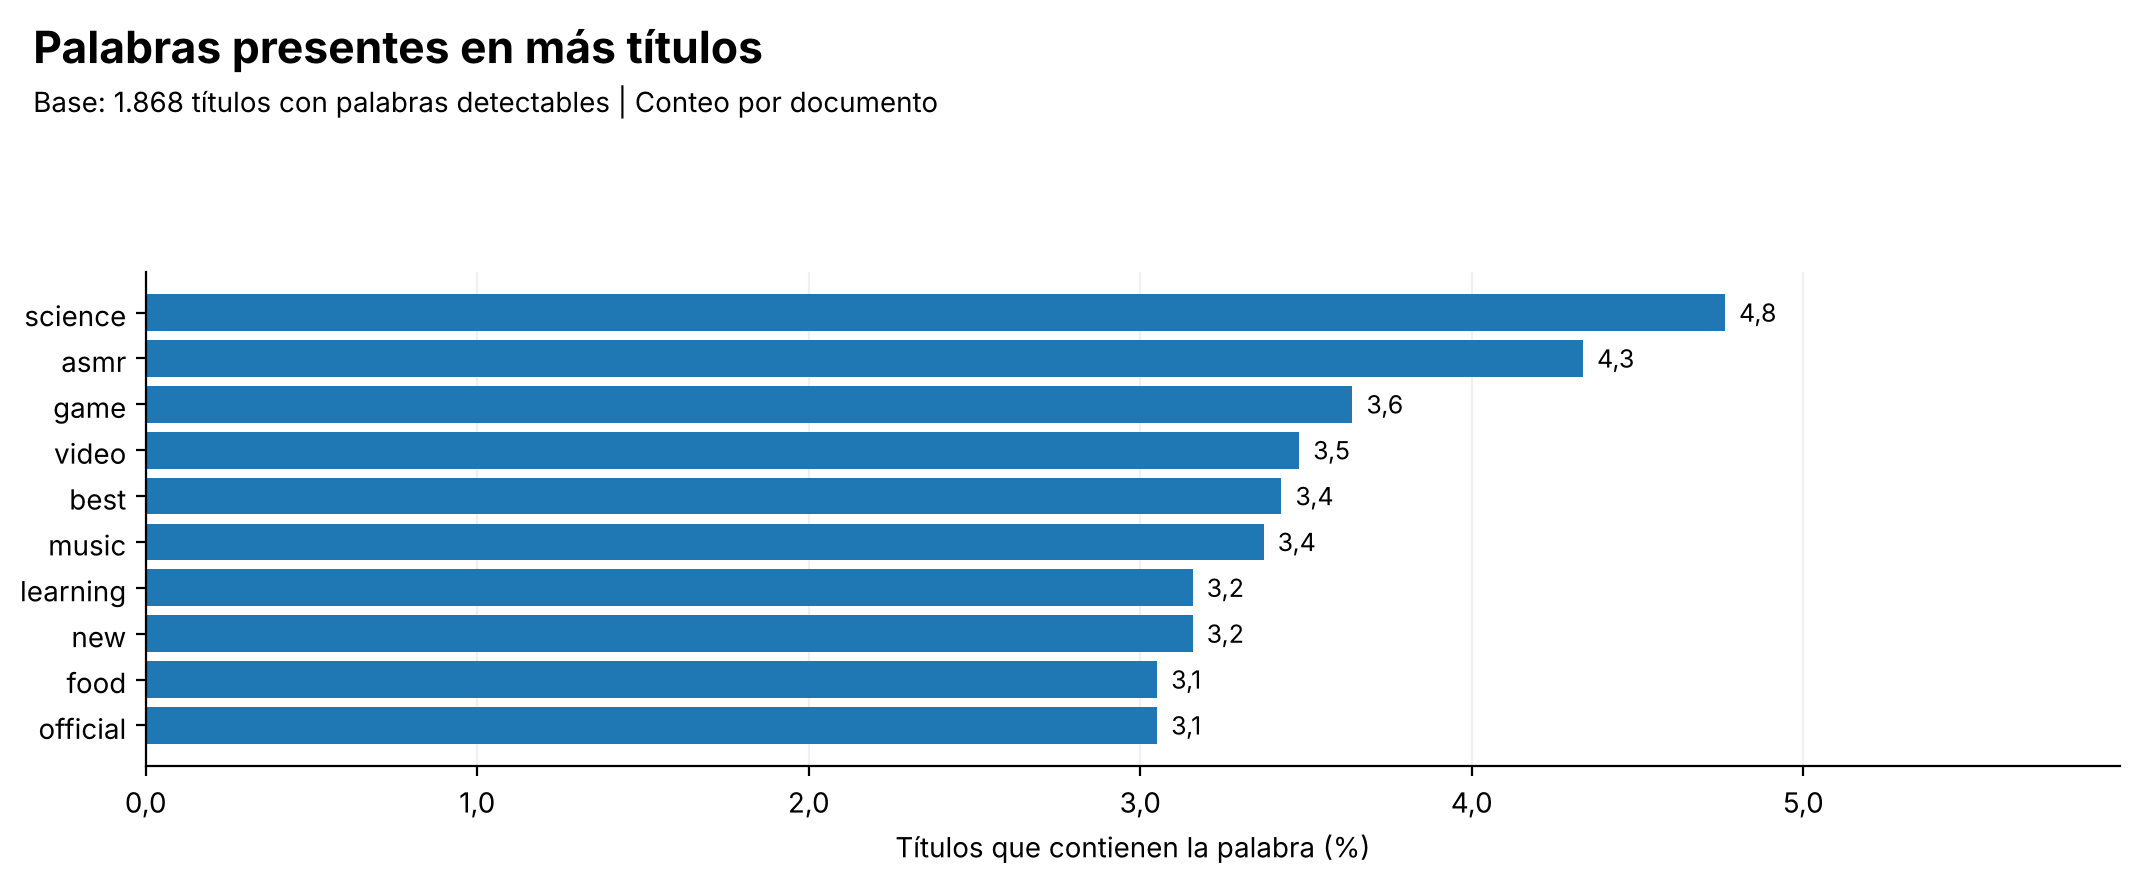

Coincidencias de la búsqueda: 43


,Video ID,titulo_legible,keywords_asociadas,Views,Likes,Comments
1826,NWONeJKn6kc,Machine Learning Course for Beginners,machine learning,11814893.0,300789.0,6254.0
1839,pHiMN_gy9mk,2020 Machine Learning Roadmap (95% valid for 2...,machine learning,10817160.0,176978.0,7152.0
1846,OuC3wgp1Fnw,How I Learnt Machine Learning In 6 Steps (3 mo...,machine learning,7497071.0,463331.0,21849.0
1851,EuBBz3bI-aA,Machine Learning Fundamentals: Bias and Variance,machine learning,5028230.0,109335.0,2712.0
1821,ukzFI9rgwfU,Machine Learning Basics | What Is Machine Lear...,machine learning,2317183.0,43189.0,1155.0
1823,HcqpanDadyQ,What is Machine Learning?,machine learning,2278698.0,38776.0,566.0
1835,KNAWp2S3w94,Intro to Machine Learning (ML Zero to Hero - P...,machine learning,1651599.0,34464.0,822.0
1822,GwIo3gDZCVQ,Machine Learning Full Course - Learn Machine L...,machine learning,1456270.0,36835.0,1265.0
1838,Rt6beTKDtqY,The Mathematics of Machine Learning,machine learning,1432027.0,27736.0,692.0
1493,5q87K1WaoFI,Computer Scientist Explains Machine Learning i...,computer science | machine learning,1407319.0,42940.0,1735.0


In [11]:
titulos_texto = videos.loc[videos["n_palabras_titulo"]>0,"titulo_normalizado"]
vocabulario,vector_conteo,matriz_conteo = tabla_vocabulario(titulos_texto,TOP)
display(vocabulario.head(TOP).round(2))
barras(vocabulario.head(TOP)["Término"],vocabulario.head(TOP)["Porcentaje"],
 "Palabras presentes en más títulos",f"Base: {numero(len(titulos_texto))} títulos con palabras detectables | Conteo por documento",
 "05_vocabulario","Títulos que contienen la palabra (%)",1)
FILTRO_TITULO = "machine learning"
consulta = videos[videos["titulo_normalizado"].str.contains(normalizar(FILTRO_TITULO),regex=False,na=False)][
    ["Video ID","titulo_legible","keywords_asociadas","Views","Likes","Comments"]].sort_values("Views",ascending=False)
print("Coincidencias de la búsqueda:",numero(len(consulta)))
display(consulta.head(10))

## Celda 12. Representar y agrupar títulos con PLN

TF-IDF representa el texto; LSA reduce dimensiones; K-Means reúne títulos parecidos. Son grupos exploratorios, no temas certificados ni categorías de éxito. La silueta mide separación geométrica, no calidad semántica.

,Grupo,Videos,Términos descriptivos,Mediana_vistas,Título de ejemplo
0,1,95,"asmr, mukbang, 먹방, eating, sounds",319387.0,ASMR Gaming 😴 Fortnite Tryhard Squad Win! Rela...
1,2,176,"minecraft, food, business, vs, challenge",722223.0,The most EXPENSIVE thing I own.
2,3,478,"nintendo, tech, reaction, marvel, crypto",210837.0,Apple Pay Is Killing the Physical Wallet After...
3,4,381,"literature, game, video, history, animals",691573.0,Best Tech/EDC Gifts Under $50 for Father's Day...
4,5,245,"cube, interview, xbox, rubik's, google",2009963.0,10 Coolest Gadgets and Inventions That Will Bl...
5,6,481,"science, data, computer, computer science, lea...",674979.0,How Biden's student loan forgiveness program w...


Silueta coseno: 0.107 | LSA: 50 componentes
Silueta cercana a 0 sugiere solapamiento; no confirma que los temas tengan sentido.
Videos fuera del agrupamiento: 13


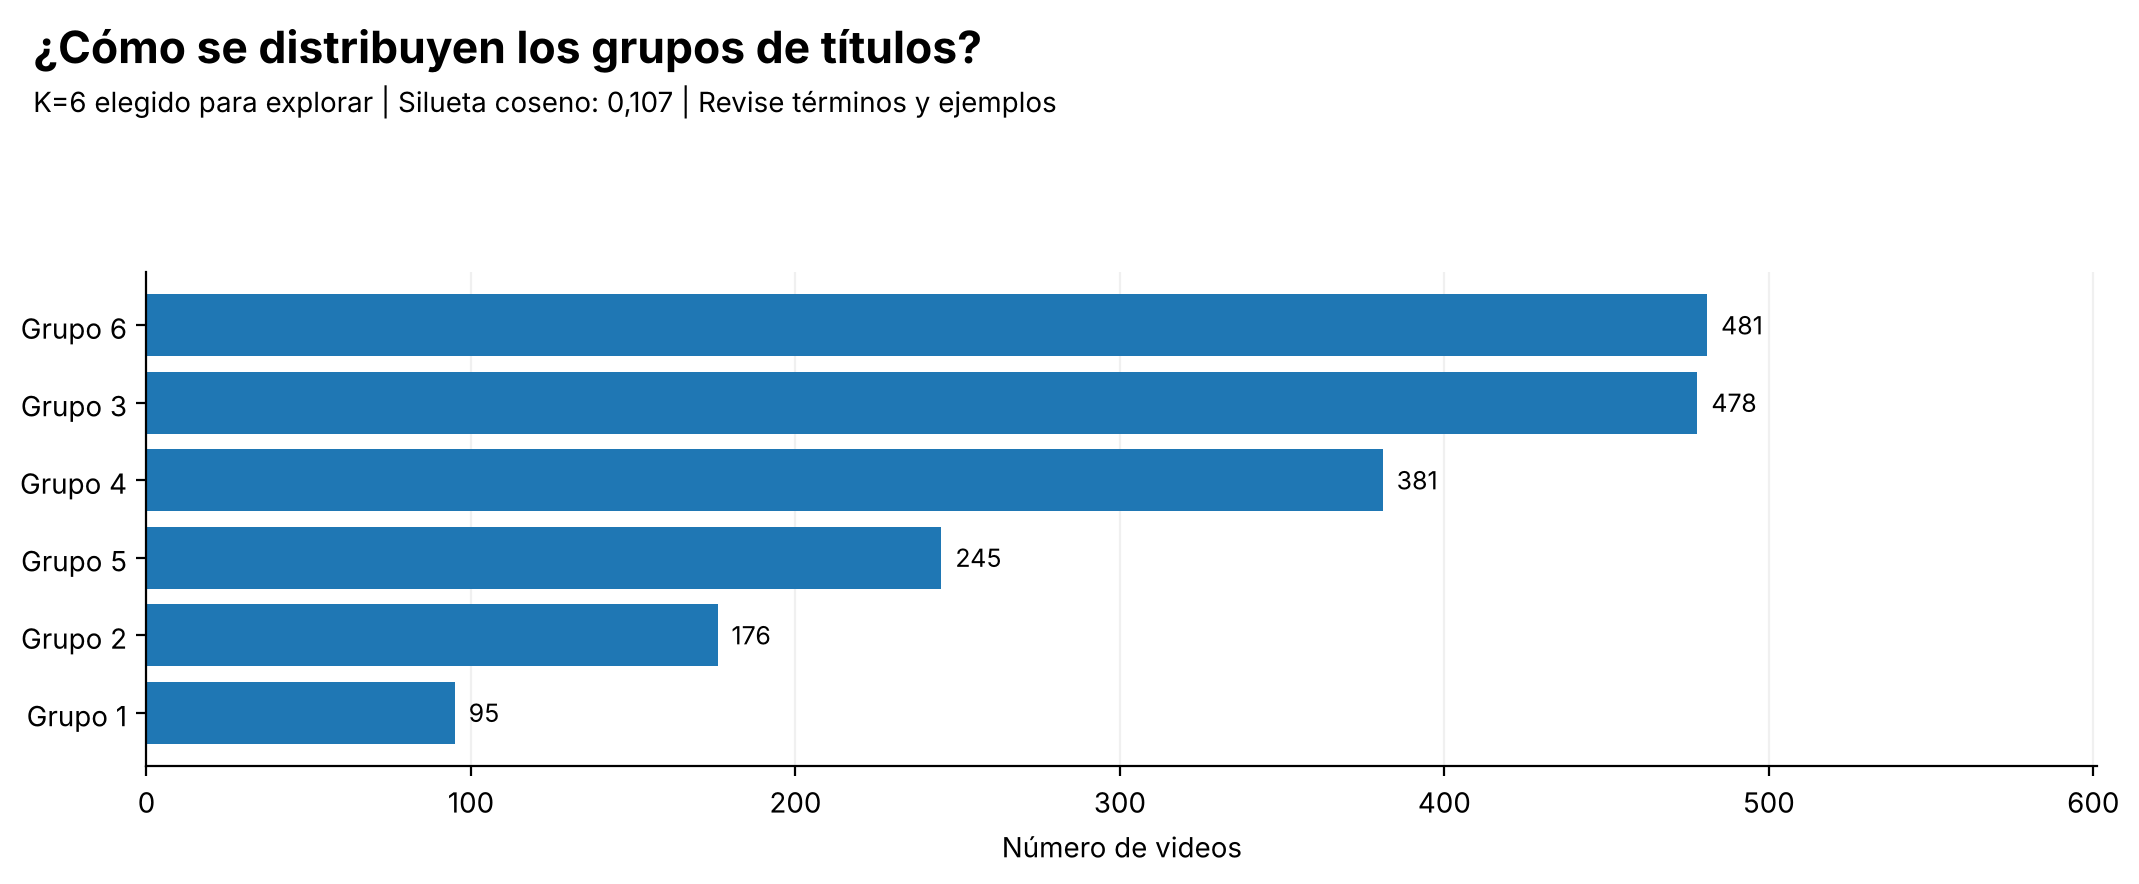

PosixPath('salida_videos/graficos/06_grupos.png')

In [12]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
indices_texto = videos.index[videos["n_palabras_titulo"]>0]
vec_titulos = TfidfVectorizer(token_pattern=PATRON,lowercase=False,
    stop_words=sorted(STOP),ngram_range=(1,2),min_df=2,max_df=.95,max_features=12000,sublinear_tf=True)
matriz_titulos = vec_titulos.fit_transform(videos.loc[indices_texto,"titulo_normalizado"])
# Se excluyen del agrupamiento los títulos cuyo vocabulario quedó completamente vacío.
no_vacios = np.asarray(matriz_titulos.getnnz(axis=1)>0).ravel()
indices_cluster = indices_texto[no_vacios]
X_titulos = matriz_titulos[no_vacios]
componentes = min(50,X_titulos.shape[1]-1,X_titulos.shape[0]-1)
if componentes<2 or not 2<=K_GRUPOS<min(len(indices_cluster),30):
    raise ValueError("Revise el número de grupos o la cantidad de títulos con vocabulario útil.")
lsa = TruncatedSVD(n_components=componentes,random_state=SEMILLA)
with threadpool_limits(limits=2):
    X_lsa = Normalizer(copy=False).fit_transform(lsa.fit_transform(X_titulos))
    agrupador = KMeans(n_clusters=K_GRUPOS,n_init=10,random_state=SEMILLA)
    grupos = agrupador.fit_predict(X_lsa)
    silueta = silhouette_score(X_lsa,grupos,metric="cosine",
        sample_size=min(1000,len(grupos)),random_state=SEMILLA)
videos["grupo_textual"] = pd.Series(pd.NA,index=videos.index,dtype="Int64")
videos.loc[indices_cluster,"grupo_textual"] = grupos+1
terminos = vec_titulos.get_feature_names_out()
filas_grupos=[]
for g in range(K_GRUPOS):
    posiciones = np.flatnonzero(grupos==g)
    pesos = np.asarray(X_titulos[posiciones].mean(axis=0)).ravel()
    top_terminos = terminos[np.argsort(pesos)[-5:][::-1]]
    subconjunto = videos.loc[indices_cluster[posiciones]]
    filas_grupos.append({"Grupo":g+1,"Videos":len(posiciones),
        "Términos descriptivos":", ".join(top_terminos),
        "Mediana_vistas":subconjunto["Views"].median(),
        "Título de ejemplo":subconjunto["titulo_legible"].iloc[0]})
resumen_grupos = pd.DataFrame(filas_grupos)
display(resumen_grupos)
print("Silueta coseno:",round(silueta,3),"| LSA:",componentes,"componentes")
print("Silueta cercana a 0 sugiere solapamiento; no confirma que los temas tengan sentido.")
print("Videos fuera del agrupamiento:",int(videos["grupo_textual"].isna().sum()))
resumen_ordenado = resumen_grupos.sort_values("Videos",ascending=False)
barras([f"Grupo {g}" for g in resumen_ordenado["Grupo"]],resumen_ordenado["Videos"],
 "¿Cómo se distribuyen los grupos de títulos?",
 f"K={K_GRUPOS} elegido para explorar | Silueta coseno: {numero(silueta,3)} | Revise términos y ejemplos",
 "06_grupos","Número de videos",0)

## Celda 13. Relaciones estadísticas y títulos

Spearman resume asociaciones monotónicas sin exigir normalidad. Se informa el número de pares válidos. No se calculan p-valores ni se afirma causalidad; las vistas pueden estar afectadas por antigüedad, canal y tema.

,Variable A,Variable B,Pares válidos,Spearman rho
0,n_palabras_titulo,Views,1867,-0.279
1,n_caracteres_titulo,Views,1867,-0.271
2,Likes,Views,1861,0.949
3,Comments,Views,1865,0.839
4,n_palabras_titulo,interacciones_por_100_vistas,1859,0.032


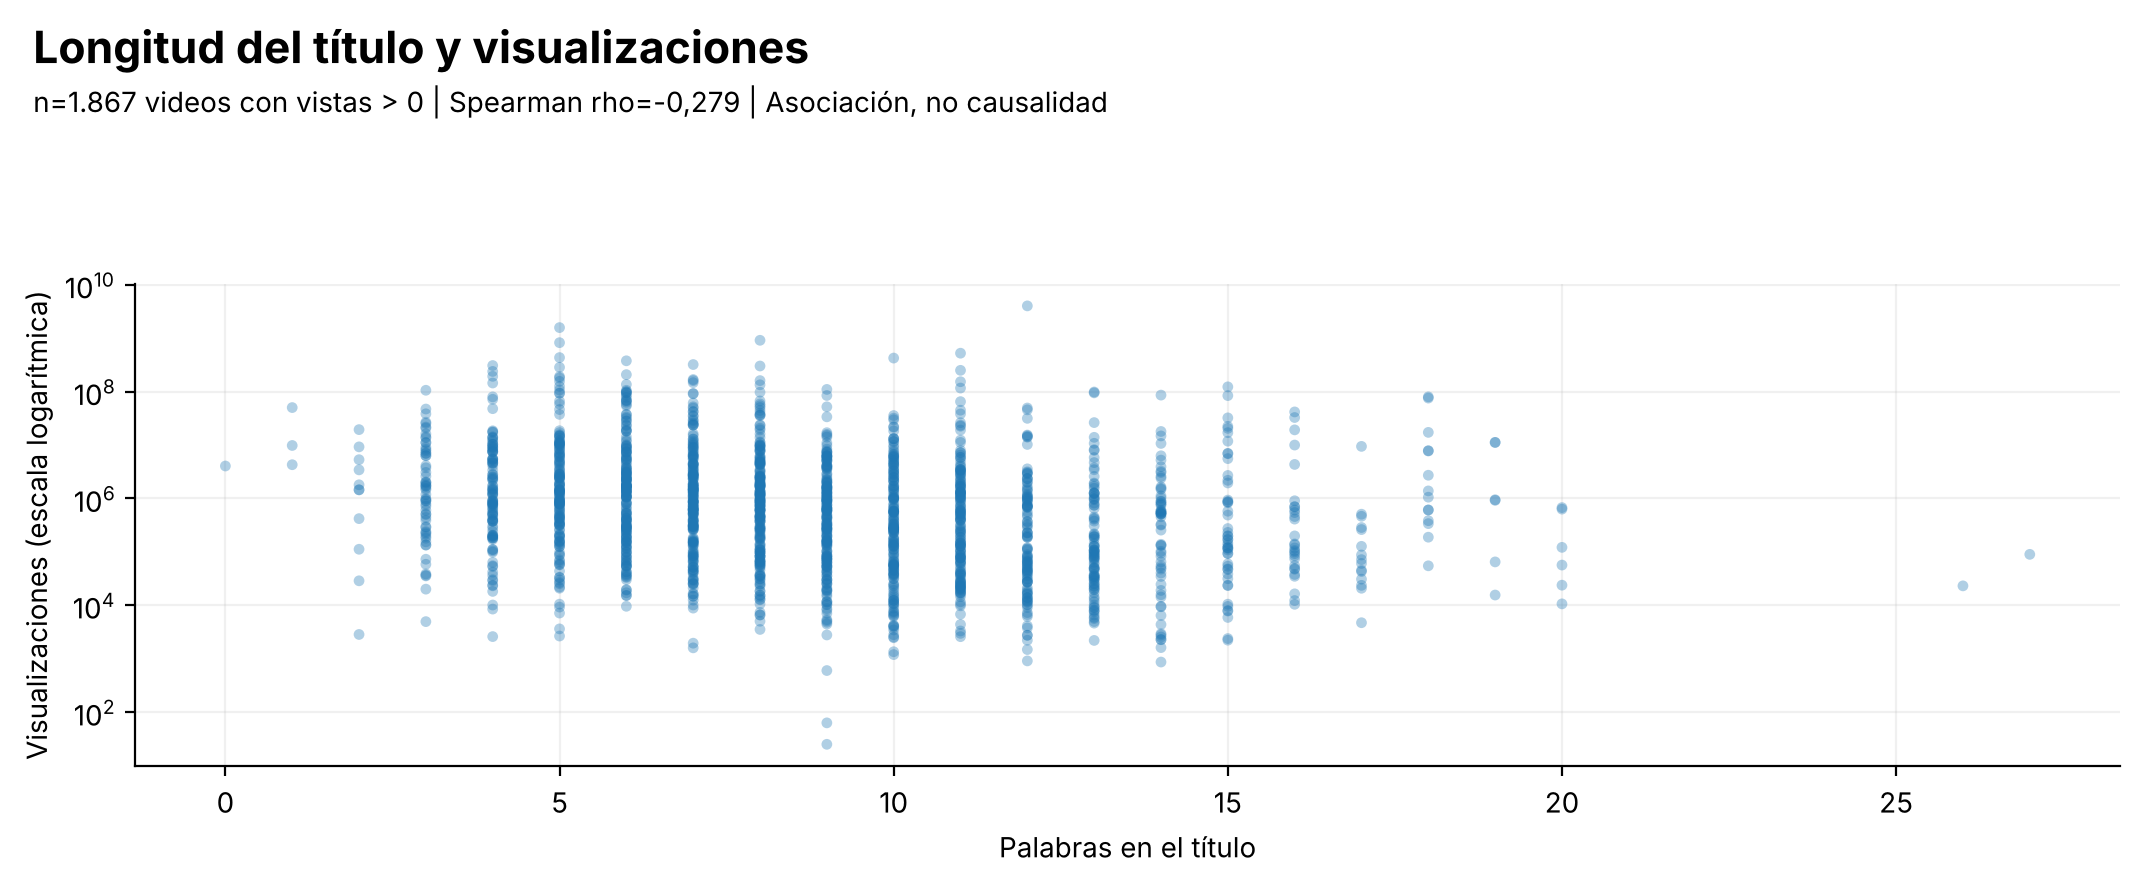

El eje vertical es logarítmico: distancias iguales representan multiplicaciones, no sumas.


In [13]:
from scipy.stats import spearmanr
pares = [("n_palabras_titulo","Views"),("n_caracteres_titulo","Views"),
         ("Likes","Views"),("Comments","Views"),("n_palabras_titulo","interacciones_por_100_vistas")]
filas=[]
for a,b in pares:
    completos=videos[[a,b]].dropna()
    rho=float(spearmanr(completos[a],completos[b]).statistic) if len(completos)>2 and completos[a].nunique()>1 and completos[b].nunique()>1 else np.nan
    filas.append({"Variable A":a,"Variable B":b,"Pares válidos":len(completos),"Spearman rho":rho})
correlaciones=pd.DataFrame(filas)
display(correlaciones.round(3))
dispersion=videos.loc[videos["Views"].gt(0),["n_palabras_titulo","Views"]].dropna()
rho_grafico=float(spearmanr(dispersion["n_palabras_titulo"],dispersion["Views"]).statistic)
fig,ax=eje("Longitud del título y visualizaciones",
    f"n={numero(len(dispersion))} videos con vistas > 0 | Spearman rho={numero(rho_grafico,3)} | Asociación, no causalidad")
ax.scatter(dispersion["n_palabras_titulo"],dispersion["Views"],alpha=.35,s=15,edgecolors="none")
ax.set_yscale("log")
ax.set_xlabel("Palabras en el título");ax.set_ylabel("Visualizaciones (escala logarítmica)")
ax.grid(alpha=.18)
guardar_grafico(fig,"07_longitud_vistas")
print("El eje vertical es logarítmico: distancias iguales representan multiplicaciones, no sumas.")

## Celda 14. Interpretación del estudiante y hallazgos automáticos

Complete sus respuestas. Una recomendación debe distinguir entre lo observado y lo que aún requiere validación.

In [14]:
RESPUESTAS={
 "¿Por qué el número de filas no equivale al número de videos?":"Por completar.",
 "¿Qué diferencia observa entre media y mediana de visualizaciones?":"Por completar.",
 "¿Qué nombre daría a dos grupos de títulos y con qué evidencia?":"Por completar.",
 "¿Qué permite y qué no permite concluir la correlación?":"Por completar.",
 "¿Qué decisión exploratoria propondría y qué datos adicionales necesitaría?":"Por completar."
}
primera_keyword=ranking_vistas.iloc[0]
HALLAZGOS=[
 f"Se consolidaron {numero(len(videos))} videos únicos a partir de {numero(len(original))} registros. No se sumaron filas repetidas del mismo video.",
 f"La mediana de visualizaciones es {numero(mediana_vistas)} y el promedio {numero(media_vistas)}; se reportan ambas medidas para mostrar la asimetría.",
 f"Los {numero(n10)} videos más vistos concentran {numero(cuota_top10,1)}% de las visualizaciones conocidas de esta muestra.",
 f"Entre grupos con al menos {MIN_VIDEOS_POR_KEYWORD} observaciones válidas, {primera_keyword['Keyword']} presenta la mayor mediana de vistas: {numero(primera_keyword['Mediana_vistas'])}.",
 f"La agrupación de títulos produjo {K_GRUPOS} grupos exploratorios; su silueta coseno es {numero(silueta,3)}. Los nombres deben validarse leyendo títulos representativos."
]
for h in HALLAZGOS: print(h)

Se consolidaron 1.869 videos únicos a partir de 1.881 registros. No se sumaron filas repetidas del mismo video.
La mediana de visualizaciones es 589.907 y el promedio 11.653.890; se reportan ambas medidas para mostrar la asimetría.
Los 187 videos más vistos concentran 88,6% de las visualizaciones conocidas de esta muestra.
Entre grupos con al menos 10 observaciones válidas, mrbeast presenta la mayor mediana de vistas: 65.074.742.
La agrupación de títulos produjo 6 grupos exploratorios; su silueta coseno es 0,107. Los nombres deben validarse leyendo títulos representativos.


## Celda 15. Preparar la plantilla PDF

La plantilla incorpora datos de esta ejecución, gráficos y sus respuestas sin enviar información a un servicio de IA.

In [15]:
# Estas funciones organizan el informe. No alteran los resultados del análisis.
from xml.sax.saxutils import escape
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image as ImagenPDF, PageBreak, KeepTogether)
from PIL import Image as ImagenPIL

ESTILOS = getSampleStyleSheet()
ESTILOS.add(ParagraphStyle(name="PortadaPLN", fontName="Helvetica-Bold",
    fontSize=26, leading=29, spaceAfter=12, textColor=colors.HexColor("#15314B")))
ESTILOS.add(ParagraphStyle(name="SeccionPLN", fontName="Helvetica-Bold",
    fontSize=15, leading=19, spaceBefore=8, spaceAfter=10,
    textColor=colors.HexColor("#15314B")))
ESTILOS.add(ParagraphStyle(name="CuerpoPLN", fontName="Helvetica",
    fontSize=10, leading=14, spaceAfter=8))
ESTILOS.add(ParagraphStyle(name="NotaPLN", fontName="Helvetica",
    fontSize=8, leading=11, spaceAfter=6))
ESTILOS.add(ParagraphStyle(name="CeldaPLN", fontName="Helvetica", fontSize=8, leading=10))
ESTILOS.add(ParagraphStyle(name="KpiPLN", fontName="Helvetica-Bold", fontSize=19,
    leading=24, spaceAfter=3, textColor=colors.HexColor("#15314B")))
ANCHO_PDF = A4[0] - 88

def texto_pdf(valor):
    # Helvetica cubre el español. Los textos originales multilingües se conservan
    # íntegros en los CSV; en el PDF se sustituyen glifos no disponibles.
    original = str(valor).replace("\x00", "")
    seguro = "".join(ch if ch.encode("cp1252", errors="ignore") else "\ufffd" for ch in original)
    return re.sub(r"\ufffd+", "[ver CSV]", seguro)

def parrafo(texto, estilo="CuerpoPLN"):
    return Paragraph(escape(texto_pdf(texto)).replace("\n", "<br/>"), ESTILOS[estilo])

def tabla_pdf(tabla, anchos=None, max_filas=15):
    t = tabla.head(max_filas).copy()
    def celda(x):
        return parrafo("N/D" if pd.isna(x) else str(x), "CeldaPLN")
    datos = [[celda(x) for x in t.columns]] + [[celda(x) for x in fila]
             for fila in t.itertuples(index=False, name=None)]
    anchos = anchos or [ANCHO_PDF / len(t.columns)] * len(t.columns)
    objeto = Table(datos, colWidths=anchos, repeatRows=1, hAlign="LEFT")
    objeto.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#EAF0F4")),
        ("LINEBELOW", (0,0), (-1,0), 0.8, colors.HexColor("#8CA0B1")),
        ("LINEBELOW", (0,1), (-1,-1), 0.3, colors.HexColor("#DEE4E9")),
        ("VALIGN", (0,0), (-1,-1), "TOP"),
        ("TOPPADDING", (0,0), (-1,-1), 6), ("BOTTOMPADDING", (0,0), (-1,-1), 6),
        ("LEFTPADDING", (0,0), (-1,-1), 7), ("RIGHTPADDING", (0,0), (-1,-1), 7)]))
    return objeto

def indicadores_pdf(items):
    datos = [[ [parrafo(valor, "KpiPLN"), parrafo(nombre, "NotaPLN")]
              for nombre, valor in items ]]
    t = Table(datos, colWidths=[ANCHO_PDF/len(items)]*len(items), hAlign="LEFT")
    t.setStyle(TableStyle([("BACKGROUND", (0,0),(-1,-1),colors.HexColor("#F2F5F7")),
      ("VALIGN", (0,0),(-1,-1),"TOP"), ("TOPPADDING", (0,0),(-1,-1),10),
      ("BOTTOMPADDING", (0,0),(-1,-1),10), ("LEFTPADDING", (0,0),(-1,-1),10)]))
    return t

def imagen_pdf(nombre, alto_max=223):
    ruta = GRAFICOS / (nombre + ".png")
    with ImagenPIL.open(ruta) as im:
        w, h = im.size
    escala = min(ANCHO_PDF/w, alto_max/h)
    return ImagenPDF(str(ruta), width=w*escala, height=h*escala, hAlign="LEFT")

def pagina_graficos(elementos, titulo, graficos, notas):
    elementos.extend([PageBreak(), parrafo(titulo, "SeccionPLN")])
    for nombre, nota in zip(graficos, notas):
        elementos.extend([imagen_pdf(nombre), Spacer(1,5), parrafo(nota, "NotaPLN"), Spacer(1,8)])

def pie_pagina(canvas, doc):
    canvas.saveState()
    canvas.setStrokeColor(colors.HexColor("#D5DFE7"))
    canvas.line(44, 42, A4[0]-44, 42)
    canvas.setFont("Helvetica", 8)
    canvas.drawString(44, 29, "PROCESAMIENTO DE LENGUAJE NATURAL | Informe reproducible")
    canvas.drawRightString(A4[0]-44, 29, f"{doc.page}")
    canvas.restoreState()

def crear_pdf(elementos, nombre):
    ruta = SALIDA/nombre
    doc = SimpleDocTemplate(str(ruta), pagesize=A4, rightMargin=44, leftMargin=44,
          topMargin=42, bottomMargin=56, title=TITULO_INFORME, author=ESTUDIANTE)
    doc.build(elementos, onFirstPage=pie_pagina, onLaterPages=pie_pagina)
    return ruta

print("Plantilla del informe preparada.")

Plantilla del informe preparada.


## Celda 16. Generar el informe gerencial en PDF

El informe distingue alcance, interacción registrada y evidencia lingüística. Las cifras corresponden al CSV cargado, no a YouTube en tiempo real.

In [16]:
TITULO_INFORME="Títulos de YouTube | Análisis de PLN y estadísticas"
contenido=[parrafo("LABORATORIO 02 / INFORME GERENCIAL","NotaPLN"),
 parrafo("Títulos, temas\ny rendimiento de videos","PortadaPLN"),
 parrafo(f"Estudiante: {ESTUDIANTE} | Grupo: {GRUPO}\nAnálisis: {FECHA_ANALISIS}","NotaPLN"),
 indicadores_pdf([("Videos únicos",numero(len(videos))),
                  ("Mediana de vistas",numero(mediana_vistas)),
                  ("Vistas del top 10%",numero(cuota_top10,1)+"%")]),Spacer(1,12),
 parrafo("Resumen para la toma de decisiones","SeccionPLN")]
for h in HALLAZGOS[:3]:contenido.append(parrafo(h))
contenido.extend([parrafo("Control de calidad","SeccionPLN"),tabla_pdf(auditoria,[ANCHO_PDF*.78,ANCHO_PDF*.22]),
 Spacer(1,8),parrafo(f"Fuente: videos-stats.csv suministrado para la clase. Publicaciones entre {fecha_min.date()} y {fecha_max.date()}. La fecha de captura y el método de muestreo no están documentados.","NotaPLN")])
pagina_graficos(contenido,"01 / Comparaciones por palabra clave",["01_keyword_vistas","02_keyword_interaccion"],[
 "Se compara la mediana, no el total, y se informa el tamaño de cada grupo. Keyword no es necesariamente una categoría oficial; un video puede pertenecer a varios grupos.",
 "Fórmula por video: 100 × (Likes + Comments) / Views. Después se calcula la mediana del grupo. No es el porcentaje de usuarios que interactuó ni una tasa oficial de engagement."])
pagina_graficos(contenido,"02 / Distribución del alcance",["03_top_videos","04_concentracion"],[
 "El ranking usa videos únicos y visualizaciones conocidas. Los títulos completos y los identificadores se incluyen en los CSV de salida.",
 "La curva ordena videos de mayor a menor número de vistas; no muestra crecimiento temporal. Los videos con vistas faltantes se excluyen del denominador, no se convierten en cero."])
pagina_graficos(contenido,"03 / Lenguaje y agrupación exploratoria",["05_vocabulario","06_grupos"],[
 "Frecuencia documental sobre títulos con palabras detectables. Las listas de palabras vacías de inglés y español no resuelven toda la diversidad lingüística del corpus.",
 "TF-IDF con palabras y bigramas, reducción LSA y K-Means. K es un parámetro elegido para explorar; no se buscó automáticamente el mejor número de grupos."])
contenido.extend([PageBreak(),parrafo("04 / Asociación entre texto y alcance","SeccionPLN"),
 imagen_pdf("07_longitud_vistas",alto_max=230),Spacer(1,10),
 parrafo("Las vistas del gráfico usan escala logarítmica para mostrar valores de órdenes de magnitud diferentes. Se excluyen del gráfico las vistas no positivas; la tabla de correlaciones usa todos los pares válidos para cada relación.","NotaPLN"),
 parrafo("Correlaciones descriptivas de Spearman","SeccionPLN")])
corr_pdf=correlaciones.copy();corr_pdf["Spearman rho"]=corr_pdf["Spearman rho"].map(lambda x:numero(x,3))
corr_pdf.columns=["Variable A","Variable B","n pares","rho"]
contenido.extend([tabla_pdf(corr_pdf,[ANCHO_PDF*.33,ANCHO_PDF*.37,ANCHO_PDF*.15,ANCHO_PDF*.15]),Spacer(1,10),
 parrafo("No se ajustó por antigüedad del video, audiencia del canal, idioma, promoción o tema. Una asociación observada no demuestra que aumentar o reducir palabras produzca más visualizaciones. No se reportan pruebas de significancia ni intervalos de confianza."),
 parrafo("No se conoce la fecha de captura. Por ello no se estiman crecimiento, vistas por día ni tendencias actuales de la plataforma.")])
contenido.extend([PageBreak(),parrafo("05 / Grupos, controles y acciones","SeccionPLN")])
grupos_pdf=resumen_grupos[["Grupo","Videos","Términos descriptivos"]].copy()
contenido.extend([tabla_pdf(grupos_pdf,[ANCHO_PDF*.1,ANCHO_PDF*.12,ANCHO_PDF*.78],max_filas=30),Spacer(1,10),
 parrafo(HALLAZGOS[4]),parrafo("Acciones recomendadas","SeccionPLN"),
 parrafo("Asignar nombres a los grupos únicamente después de revisar sus títulos y detectar casos fuera de tema. Comparar resultados con otros valores de K como exploración, sin presentar los grupos como una verdad del contenido."),
 parrafo("Para una decisión editorial, recolectar fecha de captura, idioma, canal y antigüedad; luego comparar videos comparables. No recomendar un título como causa de éxito a partir de esta correlación."),
 parrafo("Conteos inválidos detectados en las filas originales válidas por ID","SeccionPLN"),
 tabla_pdf(calidad_numerica,[ANCHO_PDF*.2,ANCHO_PDF*.48,ANCHO_PDF*.32]),Spacer(1,8),
 parrafo("Los negativos se trataron como desconocidos. Al repetir un video se conservó la primera fila completa, sin afirmar que fuera la más reciente. Los conflictos y todas las palabras clave quedan exportados para auditoría. La marca [ver CSV] sustituye texto no compatible con la fuente del PDF; el CSV conserva el original.","NotaPLN"),
 parrafo(estado_lemas,"NotaPLN")])
contenido.extend([PageBreak(),parrafo("06 / Interpretación y trazabilidad","SeccionPLN")])
for pregunta,respuesta in RESPUESTAS.items():contenido.extend([parrafo(pregunta,"SeccionPLN"),parrafo(respuesta)])
contenido.extend([parrafo("Documentación técnica","SeccionPLN"),
 parrafo("scikit-learn: TF-IDF y agrupación de documentos.\nhttps://scikit-learn.org/stable/modules/feature_extraction.html\nhttps://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html", "NotaPLN"),
 parrafo("NLTK: WordNetLemmatizer. https://www.nltk.org/api/nltk.stem.wordnet.html\nReportLab: Platypus. https://docs.reportlab.com/reportlab/userguide/ch5_platypus/", "NotaPLN"),
 parrafo("Los CSV de salida conservan datos originales relevantes y columnas derivadas, grupos, consultas y auditoría. metadatos.json registra versiones, parámetros y la huella SHA-256 del archivo fuente.","NotaPLN")])
RUTA_PDF=crear_pdf(contenido,"informe_videos.pdf")
print("PDF generado:",RUTA_PDF)

PDF generado: salida_videos/informe_videos.pdf


## Celda 17. Exportar el informe y las evidencias

Se descargan el PDF y un ZIP con datos depurados, análisis, gráficos y metadatos. Las asociaciones video-keyword se conservan aparte para no perder información.

In [17]:
videos_exportar=videos.copy()
videos_exportar["tokens"]=videos_exportar["tokens"].map(lambda x:json.dumps(x,ensure_ascii=False))
TABLAS_EXPORTAR={"videos_limpios":videos_exportar,"mapa_video_keyword":mapa_keywords,
 "auditoria":auditoria,"calidad_numerica":calidad_numerica,"registros_repetidos":registros_repetidos,
 "conflictos_por_video":conflictos_por_id.loc[ids_conflictivos].reset_index(),
 "rechazados_sin_id":rechazados,"estadistica_descriptiva":estadisticas,
 "indicadores":indicadores,"resumen_keyword":resumen_keyword,
 "ranking_videos":ranking_videos,"concentracion_vistas":pareto,"vocabulario_titulos":vocabulario,
 "consulta_titulos":consulta,"grupos_titulos":resumen_grupos,"correlaciones":correlaciones}

# CSV: datos y tablas para auditoría. JSON: parámetros, versiones y huella del original.
for nombre, tabla in TABLAS_EXPORTAR.items():
    tabla.to_csv(SALIDA / (nombre + ".csv"), index=False, encoding="utf-8-sig")
metadatos = {
    "estudiante": ESTUDIANTE, "grupo": GRUPO, "fecha_analisis": FECHA_ANALISIS,
    "archivo_origen": RUTA_CSV.name,
    "sha256_origen": hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest(),
    "parametros": PARAMETROS, "bibliotecas": VERSIONES,
    "python": platform.python_version(), "estado_lematizacion": estado_lemas,
    "nota": "Cifras históricas del CSV. Fecha de extracción y método de muestreo no documentados."
}
(SALIDA/"metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
zip_salida = Path(shutil.make_archive(str(SALIDA), "zip", root_dir=SALIDA))
print("Informe PDF:", RUTA_PDF)
print("Paquete con PDF, CSV, gráficos y metadatos:", zip_salida)
display(FileLink(str(RUTA_PDF)))
display(FileLink(str(zip_salida)))
if DESCARGAR_AL_FINAL:
    try:
        from google.colab import files
        files.download(str(RUTA_PDF))
        files.download(str(zip_salida))
    except ImportError:
        print("Fuera de Colab: abra los enlaces anteriores.")
print("Guarde también una copia de su cuaderno resuelto como evidencia.")

Informe PDF: salida_videos/informe_videos.pdf
Paquete con PDF, CSV, gráficos y metadatos: /tmp/w/run/salida_videos.zip


/tmp/w/run/salida_videos/informe_videos.pdf

/tmp/w/run/salida_videos.zip

Fuera de Colab: abra los enlaces anteriores.
Guarde también una copia de su cuaderno resuelto como evidencia.


### Reto de cierre
Cambie `FILTRO_TITULO` y estudie otro conjunto de títulos. Proponga nombres para dos grupos con ejemplos y contraejemplos. Compare la mediana de vistas con la proporción de interacciones; explique por qué no responden a la misma pregunta.

**Entregue:** su cuaderno resuelto, `informe_videos.pdf` y el ZIP de evidencias. Para regenerar el informe después de editar sus respuestas, ejecute las celdas 14 a 17. Si cambia K_GRUPOS, vuelva a ejecutar desde la celda 12; si cambia parámetros de carga o limpieza, ejecute desde el inicio.